In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as mt
import seaborn as sb

# 1. Loan Dataset Data Cleaning And Visulization And Complete EDA

In [2]:
loan = pd.read_csv("loan-train.csv")
loan.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


In [3]:
loan.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [4]:
loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1614 entries, 0 to 1613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            1614 non-null   object 
 1   Gender             1601 non-null   object 
 2   Married            1611 non-null   object 
 3   Dependents         1599 non-null   object 
 4   Education          1614 non-null   object 
 5   Self_Employed      1582 non-null   object 
 6   ApplicantIncome    1614 non-null   int64  
 7   CoapplicantIncome  1614 non-null   float64
 8   LoanAmount         1592 non-null   float64
 9   Loan_Amount_Term   1600 non-null   float64
 10  Credit_History     1564 non-null   float64
 11  Property_Area      1614 non-null   object 
 12  Loan_Status        1614 non-null   object 
dtypes: float64(4), int64(1), object(8)
memory usage: 164.1+ KB


In [5]:
loan.isna().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [6]:
loan['Gender'] = loan["Gender"].fillna(loan['Gender'].mode()[0])

In [7]:
loan['Married'] = loan['Married'].fillna(loan['Married'].mode()[0])

In [8]:
loan['Dependents'].value_counts()

Dependents
0     619
1     341
2     336
3+    303
Name: count, dtype: int64

In [9]:
loan['Dependents'] = loan["Dependents"].str.replace("+","")

In [10]:
loan['Dependents'] = pd.to_numeric(loan['Dependents'])

In [11]:
loan['Dependents'] = loan['Dependents'].fillna(loan['Dependents'].median())

In [12]:
loan['Self_Employed'] = loan['Self_Employed'].fillna(loan.Self_Employed.mode()[0])

<Axes: ylabel='LoanAmount'>

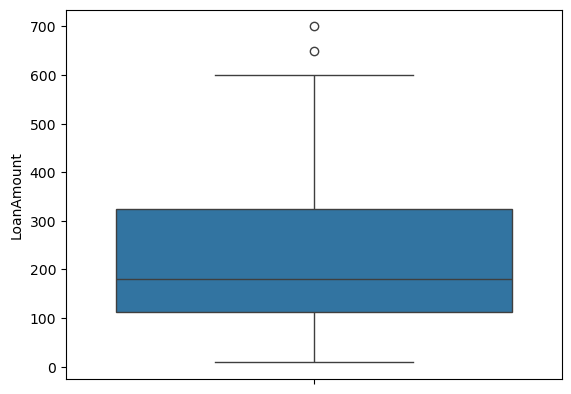

In [13]:
sb.boxplot(loan.LoanAmount)

In [14]:
loan['LoanAmount'] = loan['LoanAmount'].fillna(loan['LoanAmount'].median())

<Axes: ylabel='Loan_Amount_Term'>

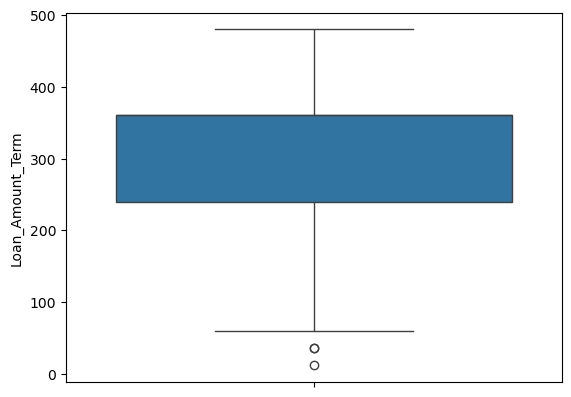

In [15]:
sb.boxplot(loan["Loan_Amount_Term"])

In [16]:
loan['Loan_Amount_Term'] = loan['Loan_Amount_Term'].fillna(loan['Loan_Amount_Term'].median())

In [17]:
loan['Credit_History'] = loan['Credit_History'].fillna(loan.Credit_History.mode()[0])

In [18]:
loan.isna().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [19]:
loan.shape

(1614, 13)

In [20]:
loan.describe(include='all')

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
count,1614,1614,1614,1614.000000,1614,1614,1614.000000,1614.000000,1614.000000,1614.000000,1614.00000,1614,1614
unique,1538,2,2,NaN,2,2,NaN,NaN,NaN,NaN,NaN,3,2
top,LP006706,Male,Yes,NaN,Graduate,No,NaN,NaN,NaN,NaN,NaN,Urban,Y
freq,3,993,928,NaN,952,1031,NaN,NaN,NaN,NaN,NaN,549,915
mean,NaN,NaN,NaN,1.200124,NaN,NaN,8746.304833,3658.722999,218.317224,291.078067,0.64684,NaN,NaN
std,NaN,NaN,NaN,1.141659,NaN,NaN,6249.885122,3291.745935,132.785377,81.798158,0.47810,NaN,NaN
min,NaN,NaN,NaN,0.000000,NaN,NaN,150.000000,0.000000,9.000000,12.000000,0.00000,NaN,NaN
25%,NaN,NaN,NaN,0.000000,NaN,NaN,3675.250000,986.250000,112.000000,240.000000,0.00000,NaN,NaN
50%,NaN,NaN,NaN,1.000000,NaN,NaN,7045.000000,2941.500000,180.000000,360.000000,1.00000,NaN,NaN
75%,NaN,NaN,NaN,2.000000,NaN,NaN,13251.000000,5893.000000,322.000000,360.000000,1.00000,NaN,NaN


In [21]:
loan.nunique()

Loan_ID              1538
Gender                  2
Married                 2
Dependents              4
Education               2
Self_Employed           2
ApplicantIncome      1455
CoapplicantIncome    1206
LoanAmount            461
Loan_Amount_Term       10
Credit_History          2
Property_Area           3
Loan_Status             2
dtype: int64

In [22]:
loan[loan['Loan_ID'].duplicated(keep=False)].sort_values('Loan_ID')

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
614,LP003002,Male,Yes,0.0,Not Graduate,Yes,8295,6148.0,330.0,360.0,0.0,Urban,Y
615,LP003002,Female,Yes,2.0,Graduate,No,13525,6635.0,217.0,180.0,0.0,Urban,Y
618,LP003029,Female,Yes,0.0,Graduate,Yes,17556,9346.0,298.0,180.0,0.0,Semiurban,Y
619,LP003029,Male,Yes,0.0,Graduate,Yes,6451,3274.0,353.0,240.0,1.0,Semiurban,N
631,LP003103,Male,No,2.0,Not Graduate,No,9952,8631.0,458.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1537,LP009399,Female,No,2.0,Graduate,No,7880,4720.0,349.0,180.0,0.0,Semiurban,Y
1570,LP009650,Female,Yes,2.0,Not Graduate,Yes,9826,5611.0,123.0,240.0,1.0,Rural,Y
1571,LP009650,Male,Yes,2.0,Graduate,Yes,9466,920.0,116.0,180.0,1.0,Rural,N
1603,LP009936,Female,No,0.0,Not Graduate,Yes,17391,7064.0,347.0,240.0,0.0,Urban,Y


In [23]:
loan['Loan_ID'].duplicated().sum()

np.int64(76)

In [24]:
loan['Loan_ID'].duplicated(keep=False).sum()

np.int64(151)

In [25]:
loan['Loan_ID'].nunique()

1538

In [26]:
loan['Gender'].value_counts()

Gender
Male      993
Female    621
Name: count, dtype: int64

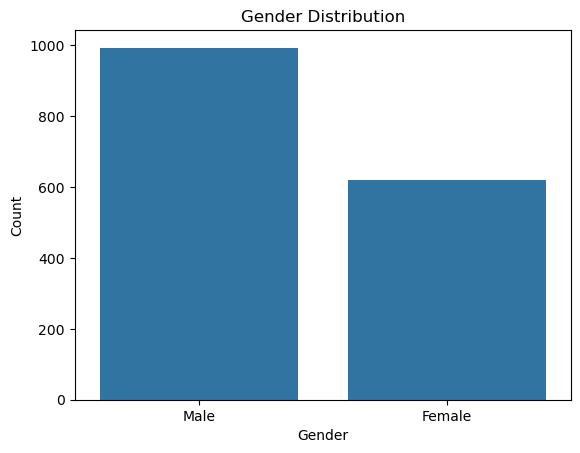

In [27]:
sb.countplot(data=loan, x='Gender')

mt.title('Gender Distribution')
mt.xlabel('Gender')
mt.ylabel('Count')
mt.show()

In [28]:
loan['Married'].value_counts()

Married
Yes    928
No     686
Name: count, dtype: int64

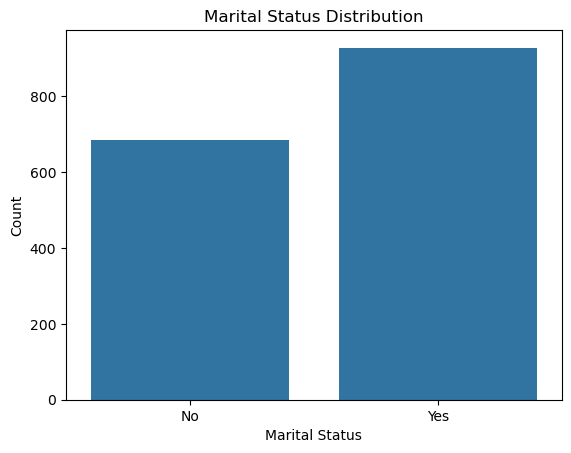

In [29]:
sb.countplot(data=loan, x='Married')

mt.title('Marital Status Distribution')
mt.xlabel('Marital Status')
mt.ylabel('Count')
mt.show()

In [30]:
loan['Dependents'].value_counts()

Dependents
0.0    619
1.0    356
2.0    336
3.0    303
Name: count, dtype: int64

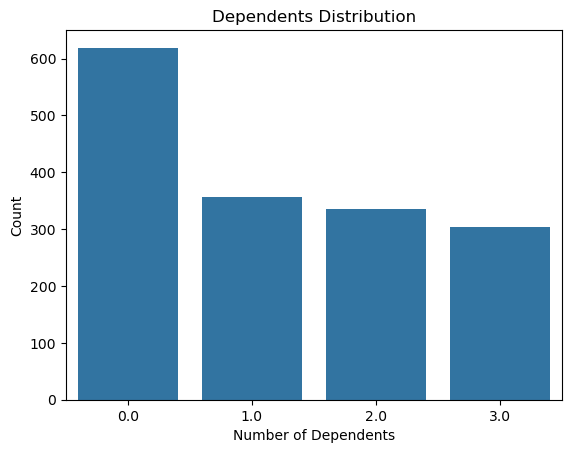

In [31]:
sb.countplot(data=loan, x='Dependents')

mt.title('Dependents Distribution')
mt.xlabel('Number of Dependents')
mt.ylabel('Count')
mt.show()

In [32]:
loan['Education'].value_counts()

Education
Graduate        952
Not Graduate    662
Name: count, dtype: int64

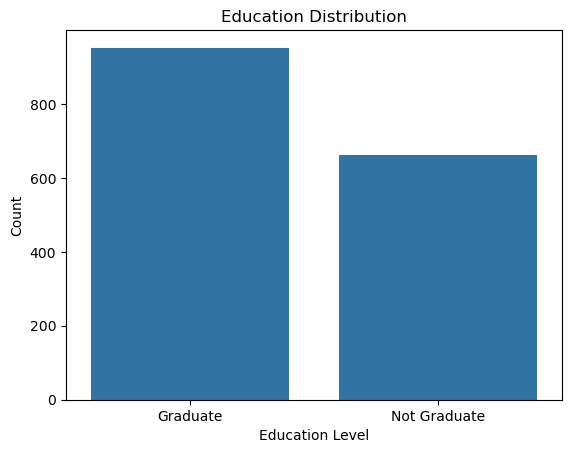

In [33]:
sb.countplot(data=loan, x="Education")
             
mt.title("Education Distribution")
mt.xlabel("Education Level")
mt.ylabel("Count")
mt.show()

In [34]:
loan['Self_Employed'].value_counts()

Self_Employed
No     1031
Yes     583
Name: count, dtype: int64

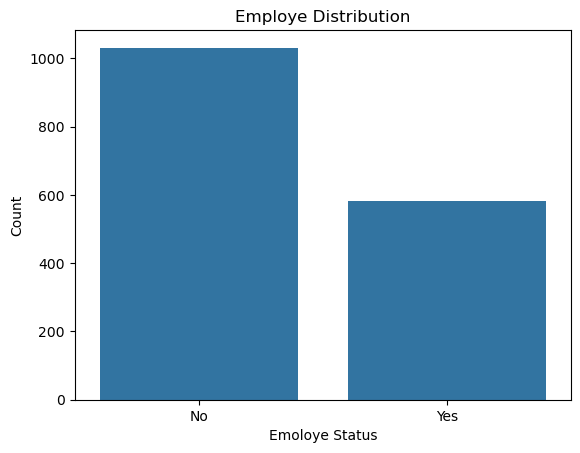

In [35]:
sb.countplot(data=loan, x="Self_Employed")
mt.title('Employe Distribution')
mt.xlabel('Emoloye Status')
mt.ylabel('Count')
mt.show()

In [36]:
loan['ApplicantIncome'].value_counts()

ApplicantIncome
2500     10
4583      6
6000      6
2600      6
5000      5
         ..
18384     1
7308      1
11328     1
18350     1
5849      1
Name: count, Length: 1455, dtype: int64

In [37]:
loan['ApplicantIncome'].describe()

count     1614.000000
mean      8746.304833
std       6249.885122
min        150.000000
25%       3675.250000
50%       7045.000000
75%      13251.000000
max      81000.000000
Name: ApplicantIncome, dtype: float64

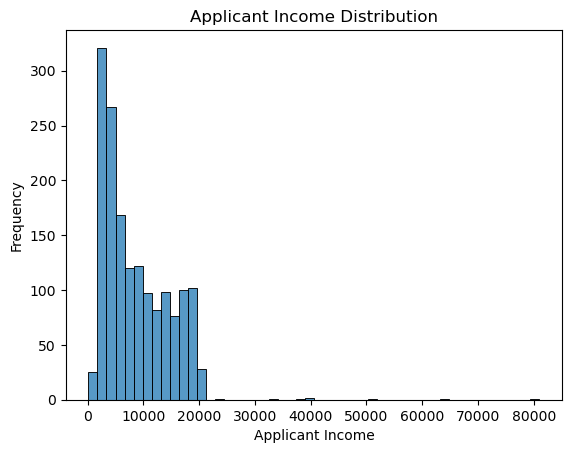

In [38]:
sb.histplot(data=loan, x='ApplicantIncome')

mt.title('Applicant Income Distribution')
mt.xlabel('Applicant Income')
mt.ylabel('Frequency')
mt.show()

In [39]:
loan['CoapplicantIncome'].value_counts()

CoapplicantIncome
0.0       273
2500.0      5
1666.0      5
2083.0      5
5625.0      4
         ... 
9242.0      1
2207.0      1
3442.0      1
6749.0      1
4196.0      1
Name: count, Length: 1206, dtype: int64

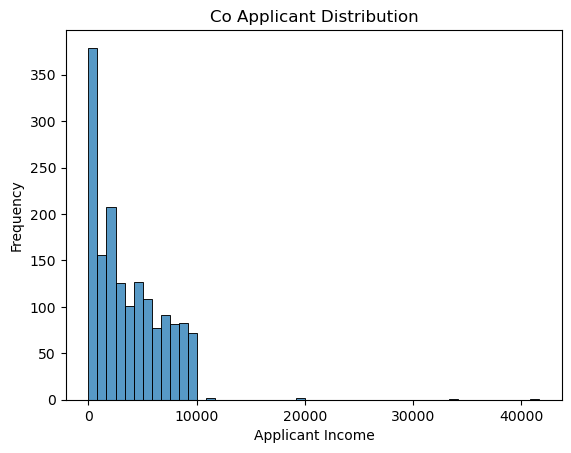

In [40]:
sb.histplot(data=loan, x="CoapplicantIncome")
mt.title("Co Applicant Distribution")
mt.xlabel("Applicant Income")
mt.ylabel("Frequency")
mt.show()

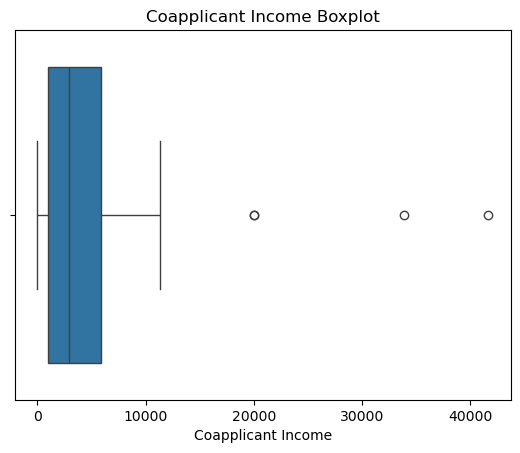

In [41]:
sb.boxplot(data=loan, x='CoapplicantIncome')

mt.title('Coapplicant Income Boxplot')
mt.xlabel('Coapplicant Income')
mt.show()

In [42]:
loan['LoanAmount'].describe()

count    1614.000000
mean      218.317224
std       132.785377
min         9.000000
25%       112.000000
50%       180.000000
75%       322.000000
max       700.000000
Name: LoanAmount, dtype: float64

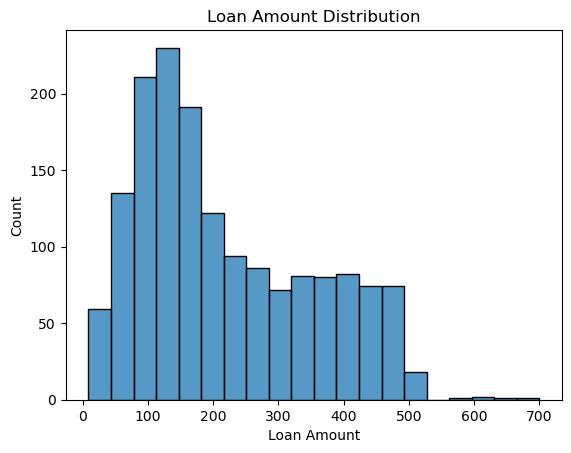

In [43]:
sb.histplot(data=loan, x="LoanAmount")
mt.title("Loan Amount Distribution")
mt.xlabel("Loan Amount")
mt.ylabel("Count")
mt.show()

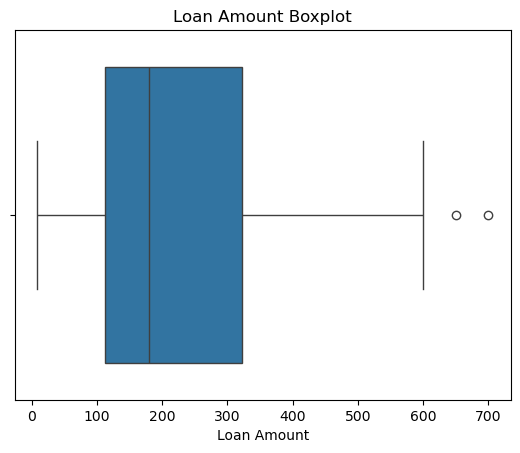

In [44]:
sb.boxplot(data=loan, x='LoanAmount')

mt.title('Loan Amount Boxplot')
mt.xlabel('Loan Amount')
mt.show()

In [45]:
loan['Loan_Amount_Term'].describe()

count    1614.000000
mean      291.078067
std        81.798158
min        12.000000
25%       240.000000
50%       360.000000
75%       360.000000
max       480.000000
Name: Loan_Amount_Term, dtype: float64

In [46]:
loan['Loan_Amount_Term'].value_counts().sort_index()

Loan_Amount_Term
12.0       1
36.0       2
60.0       2
84.0       4
120.0      3
180.0    384
240.0    331
300.0     13
360.0    859
480.0     15
Name: count, dtype: int64

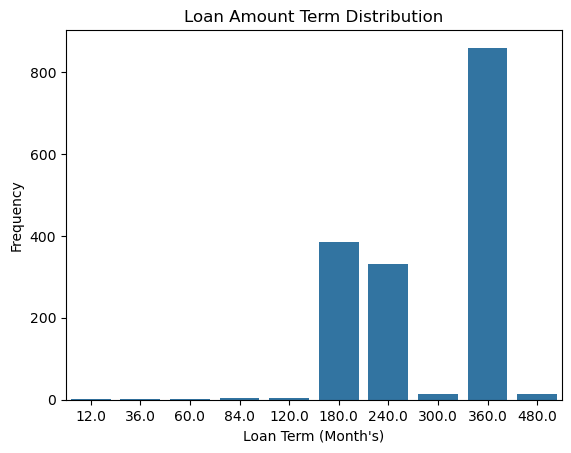

In [47]:
sb.countplot(data=loan, x="Loan_Amount_Term")
mt.title("Loan Amount Term Distribution")
mt.xlabel("Loan Term (Month's)")
mt.ylabel("Frequency")
mt.show()

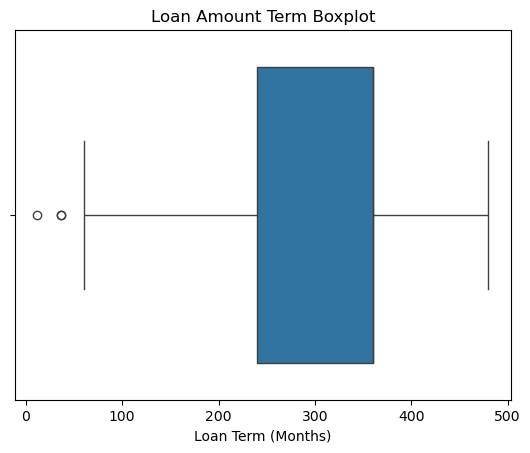

In [48]:
sb.boxplot(data=loan, x='Loan_Amount_Term')

mt.title('Loan Amount Term Boxplot')
mt.xlabel('Loan Term (Months)')
mt.show()

In [49]:
loan['Credit_History'].value_counts()

Credit_History
1.0    1044
0.0     570
Name: count, dtype: int64

In [50]:
loan['Credit_History'].describe()

count    1614.00000
mean        0.64684
std         0.47810
min         0.00000
25%         0.00000
50%         1.00000
75%         1.00000
max         1.00000
Name: Credit_History, dtype: float64

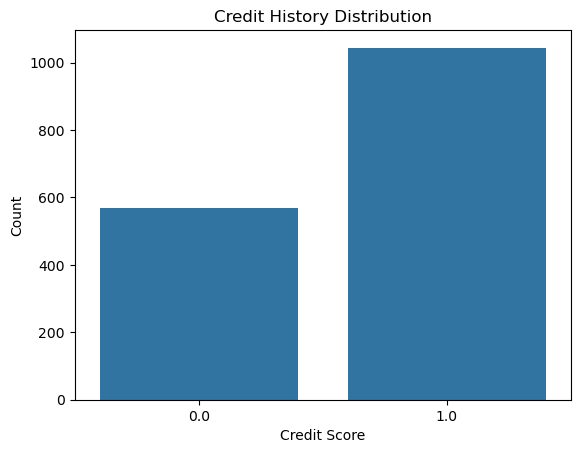

In [51]:
sb.countplot(data=loan, x='Credit_History')
mt.title('Credit History Distribution')
mt.xlabel('Credit Score')
mt.ylabel('Count')
mt.show()

In [52]:
loan['Property_Area'].describe()

count      1614
unique        3
top       Urban
freq        549
Name: Property_Area, dtype: object

In [53]:
loan['Property_Area'].value_counts()

Property_Area
Urban        549
Semiurban    545
Rural        520
Name: count, dtype: int64

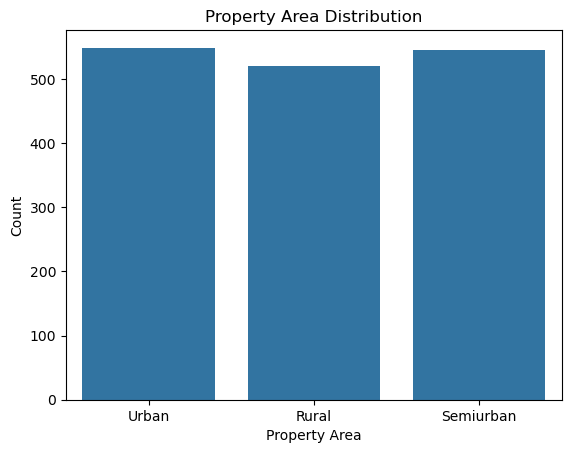

In [54]:
sb.countplot(data=loan, x='Property_Area')
mt.title("Property Area Distribution")
mt.xlabel("Property Area")
mt.ylabel("Count")
mt.show()

In [55]:
loan['Loan_Status'].value_counts()

Loan_Status
Y    915
N    699
Name: count, dtype: int64

In [56]:
loan['Loan_Status'].describe()

count     1614
unique       2
top          Y
freq       915
Name: Loan_Status, dtype: object

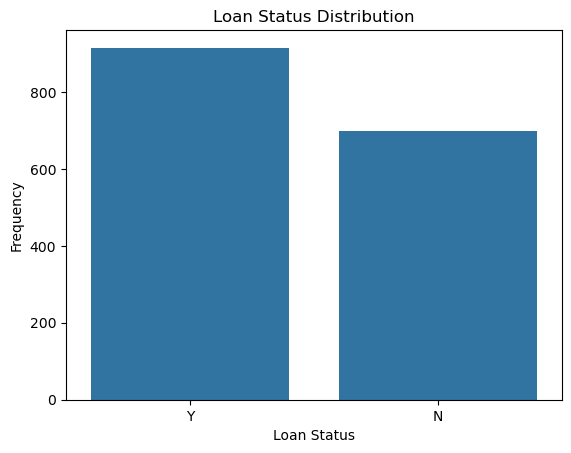

In [57]:
sb.countplot(data=loan, x="Loan_Status")
mt.title('Loan Status Distribution')
mt.xlabel('Loan Status')
mt.ylabel('Frequency')
mt.show()

In [58]:
loan.to_csv("Loan_Cleaned.csv", index=False)

# Loan Dataset – Summary
Completed
- Dataset Size: 1,614 Rows × 13 Columns
- Data Cleaning: Missing values, datatype conversion aur inconsistent values handle ki.
- Duplicate Analysis: Repeated Loan_ID investigate kiye; records delete nahi kiye.
- Univariate Analysis: All 13 columns analyzed.
- Visualizations: Countplot, Histogram, Boxplot.
- Statistical Analysis: Mean, Median, Standard Deviation, Frequency.
Status: Data Cleaning + Column-wise EDA + Visualizations completed.

# 2. Adult Dataset Data Cleaning And Visulization And Complete EDA

In [4]:
adult = pd.read_csv("adult.csv")
adult.head(100)

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,20,Private,479296,HS-grad,9,Never-married,Handlers-cleaners,Own-child,White,Male,0,0,40,United-States,<=50K
96,25,Private,235218,Bachelors,13,Never-married,Exec-managerial,Own-child,White,Female,0,0,40,United-States,<=50K
97,49,Private,164877,10th,6,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,40,United-States,<=50K
98,59,Private,272087,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,40,United-States,>50K


In [5]:
adult.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [6]:
adult.shape

(48842, 15)

In [7]:
adult.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'educational-num',
       'marital-status', 'occupation', 'relationship', 'race', 'gender',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

In [8]:
adult.isna().sum()

age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

In [9]:
adult.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [10]:
adult.age.unique()

array([25, 38, 28, 44, 18, 34, 29, 63, 24, 55, 65, 36, 26, 58, 48, 43, 20,
       37, 40, 72, 45, 22, 23, 54, 32, 46, 56, 17, 39, 52, 21, 42, 33, 30,
       47, 41, 19, 69, 50, 31, 59, 49, 51, 27, 57, 61, 64, 79, 73, 53, 77,
       80, 62, 35, 68, 66, 75, 60, 67, 71, 70, 90, 81, 74, 78, 82, 83, 85,
       76, 84, 89, 88, 87, 86])

In [11]:
adult.workclass.unique()

array(['Private', 'Local-gov', '?', 'Self-emp-not-inc', 'Federal-gov',
       'State-gov', 'Self-emp-inc', 'Without-pay', 'Never-worked'],
      dtype=object)

In [12]:
adult.workclass.mode()

0    Private
Name: workclass, dtype: object

In [13]:
adult['workclass'] = adult['workclass'].str.replace("?", "Private")

In [14]:
adult['workclass'].value_counts()

workclass
Private             36705
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

In [15]:
adult['fnlwgt'].unique()

array([226802,  89814, 336951, ..., 129912, 255835, 257302])

In [16]:
adult['education'].unique()

array(['11th', 'HS-grad', 'Assoc-acdm', 'Some-college', '10th',
       'Prof-school', '7th-8th', 'Bachelors', 'Masters', 'Doctorate',
       '5th-6th', 'Assoc-voc', '9th', '12th', '1st-4th', 'Preschool'],
      dtype=object)

In [17]:
adult['educational-num'].unique()

array([ 7,  9, 12, 10,  6, 15,  4, 13, 14, 16,  3, 11,  5,  8,  2,  1])

In [18]:
adult['marital-status'].unique()

array(['Never-married', 'Married-civ-spouse', 'Widowed', 'Divorced',
       'Separated', 'Married-spouse-absent', 'Married-AF-spouse'],
      dtype=object)

In [19]:
adult['occupation'].unique()

array(['Machine-op-inspct', 'Farming-fishing', 'Protective-serv', '?',
       'Other-service', 'Prof-specialty', 'Craft-repair', 'Adm-clerical',
       'Exec-managerial', 'Tech-support', 'Sales', 'Priv-house-serv',
       'Transport-moving', 'Handlers-cleaners', 'Armed-Forces'],
      dtype=object)

In [20]:
adult['occupation'].value_counts()

occupation
Prof-specialty       6172
Craft-repair         6112
Exec-managerial      6086
Adm-clerical         5611
Sales                5504
Other-service        4923
Machine-op-inspct    3022
?                    2809
Transport-moving     2355
Handlers-cleaners    2072
Farming-fishing      1490
Tech-support         1446
Protective-serv       983
Priv-house-serv       242
Armed-Forces           15
Name: count, dtype: int64

In [21]:
adult['occupation'] = adult['occupation'].replace('?', np.nan)

In [22]:
adult['occupation'] = adult['occupation'].fillna(adult['occupation'].mode()[0])

In [23]:
adult['relationship'].unique()

array(['Own-child', 'Husband', 'Not-in-family', 'Unmarried', 'Wife',
       'Other-relative'], dtype=object)

In [24]:
adult['race'].unique()

array(['Black', 'White', 'Asian-Pac-Islander', 'Other',
       'Amer-Indian-Eskimo'], dtype=object)

In [25]:
adult['gender'].unique()

array(['Male', 'Female'], dtype=object)

In [26]:
adult['capital-gain'].unique()

array([    0,  7688,  3103,  6418,  7298,  3908, 14084,  5178, 15024,
       99999,  2597,  2907,  4650,  6497,  1055,  5013, 27828,  4934,
        4064,  3674,  2174, 10605,  3418,   114,  2580,  3411,  4508,
        4386,  8614, 13550,  6849,  2463,  3137,  2885,  2964,  1471,
       10566,  2354,  1424,  1455,  3325,  4416, 25236,   594,  2105,
        4787,  2829,   401,  4865,  1264,  1506, 10520,  3464,  2653,
       20051,  4101,  1797,  2407,  3471,  1086,  1848, 14344,  1151,
        2993,  2290, 15020,  9386,  2202,  3818,  2176,  5455, 11678,
        7978,  7262,  6514, 41310,  3456,  7430,  2414,  2062, 34095,
        1831,  6723,  5060, 15831,  2977,  2346,  3273,  2329,  9562,
        2635,  4931,  1731,  6097,   914,  7896,  5556,  1409,  3781,
        3942,  2538,  3887, 25124,  7443,  5721,  1173,  4687,  6612,
        6767,  2961,   991,  2036,  2936,  2050,  1111,  2228, 22040,
        3432,  6360,  2009,  1639, 18481,  2387])

In [27]:
adult['capital-loss'].unique()

array([   0, 1721, 1876, 2415, 1887,  625, 1977, 2057, 1429, 1590, 1485,
       2051, 2377, 1672, 1628, 1902, 1602, 1741, 2444, 1408, 2001, 2042,
       1740, 1825, 1848, 1719, 3004, 2179, 1573, 2205, 1258, 2339, 1726,
       2258, 1340, 1504, 2559, 1668, 1974, 1980, 1564, 2547, 2002, 1669,
       1617,  323, 3175, 2472, 2174, 1579, 2129, 1510, 1735, 2282, 1870,
       1411, 1911, 1651, 1092, 1762, 2457, 2231, 2238,  653, 1138, 2246,
       2603, 2392, 1944, 1380, 2465, 1421, 3770, 1594,  213, 2149, 2824,
       1844, 2467, 2163, 1816, 1648, 2206, 2352,  419, 1539,  880,  810,
        974, 4356, 2489, 1755, 3683, 2267, 2080,  155, 3900, 2201, 2754])

In [28]:
adult['hours-per-week'].unique()

array([40, 50, 30, 32, 10, 39, 35, 48, 25, 20, 45, 47,  6, 43, 90, 54, 60,
       38, 36, 18, 24, 44, 56, 28, 16, 41, 22, 55, 14, 33, 37,  8, 12, 70,
       15, 75, 52, 84, 42, 80, 68, 99, 65,  5, 17, 72, 53, 29, 96, 21, 46,
        3,  1, 23, 49, 67, 76,  7,  2, 58, 26, 34,  4, 51, 78, 63, 31, 92,
       77, 27, 85, 13, 19, 98, 62, 66, 57, 11, 86, 59,  9, 64, 73, 61, 88,
       79, 89, 74, 69, 87, 97, 94, 82, 91, 81, 95])

In [29]:
adult['native-country'].unique()

array(['United-States', '?', 'Peru', 'Guatemala', 'Mexico',
       'Dominican-Republic', 'Ireland', 'Germany', 'Philippines',
       'Thailand', 'Haiti', 'El-Salvador', 'Puerto-Rico', 'Vietnam',
       'South', 'Columbia', 'Japan', 'India', 'Cambodia', 'Poland',
       'Laos', 'England', 'Cuba', 'Taiwan', 'Italy', 'Canada', 'Portugal',
       'China', 'Nicaragua', 'Honduras', 'Iran', 'Scotland', 'Jamaica',
       'Ecuador', 'Yugoslavia', 'Hungary', 'Hong', 'Greece',
       'Trinadad&Tobago', 'Outlying-US(Guam-USVI-etc)', 'France',
       'Holand-Netherlands'], dtype=object)

In [30]:
adult['native-country'].value_counts()

native-country
United-States                 43832
Mexico                          951
?                               857
Philippines                     295
Germany                         206
Puerto-Rico                     184
Canada                          182
El-Salvador                     155
India                           151
Cuba                            138
England                         127
China                           122
South                           115
Jamaica                         106
Italy                           105
Dominican-Republic              103
Japan                            92
Guatemala                        88
Poland                           87
Vietnam                          86
Columbia                         85
Haiti                            75
Portugal                         67
Taiwan                           65
Iran                             59
Nicaragua                        49
Greece                           49
Peru         

In [31]:
adult['native-country'].value_counts()['?']

np.int64(857)

In [32]:
adult['native-country'] = adult['native-country'].replace("?" , adult['native-country'].mode()[0])

In [33]:
adult['native-country'].value_counts()

native-country
United-States                 44689
Mexico                          951
Philippines                     295
Germany                         206
Puerto-Rico                     184
Canada                          182
El-Salvador                     155
India                           151
Cuba                            138
England                         127
China                           122
South                           115
Jamaica                         106
Italy                           105
Dominican-Republic              103
Japan                            92
Guatemala                        88
Poland                           87
Vietnam                          86
Columbia                         85
Haiti                            75
Portugal                         67
Taiwan                           65
Iran                             59
Nicaragua                        49
Greece                           49
Peru                             46
Ecuador      

In [34]:
adult['native-country'].unique()

array(['United-States', 'Peru', 'Guatemala', 'Mexico',
       'Dominican-Republic', 'Ireland', 'Germany', 'Philippines',
       'Thailand', 'Haiti', 'El-Salvador', 'Puerto-Rico', 'Vietnam',
       'South', 'Columbia', 'Japan', 'India', 'Cambodia', 'Poland',
       'Laos', 'England', 'Cuba', 'Taiwan', 'Italy', 'Canada', 'Portugal',
       'China', 'Nicaragua', 'Honduras', 'Iran', 'Scotland', 'Jamaica',
       'Ecuador', 'Yugoslavia', 'Hungary', 'Hong', 'Greece',
       'Trinadad&Tobago', 'Outlying-US(Guam-USVI-etc)', 'France',
       'Holand-Netherlands'], dtype=object)

In [35]:
adult['income'].unique()

array(['<=50K', '>50K'], dtype=object)

In [36]:
adult['age'].describe()

count    48842.000000
mean        38.643585
std         13.710510
min         17.000000
25%         28.000000
50%         37.000000
75%         48.000000
max         90.000000
Name: age, dtype: float64

In [37]:
adult['age'].value_counts()

age
36    1348
35    1337
33    1335
23    1329
31    1325
      ... 
88       6
85       5
87       3
89       2
86       1
Name: count, Length: 74, dtype: int64

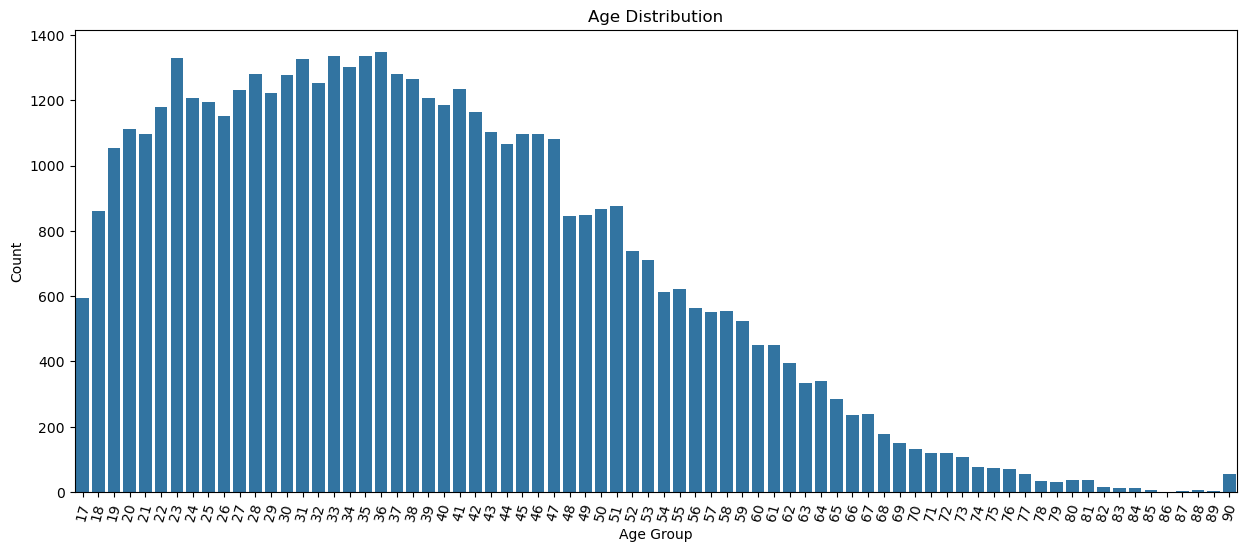

In [38]:
mt.figure(figsize=(15,6))

sb.countplot(data=adult, x='age')
mt.title("Age Distribution")
mt.xlabel("Age Group")
mt.ylabel("Count")
mt.xticks(rotation=75)
mt.show()

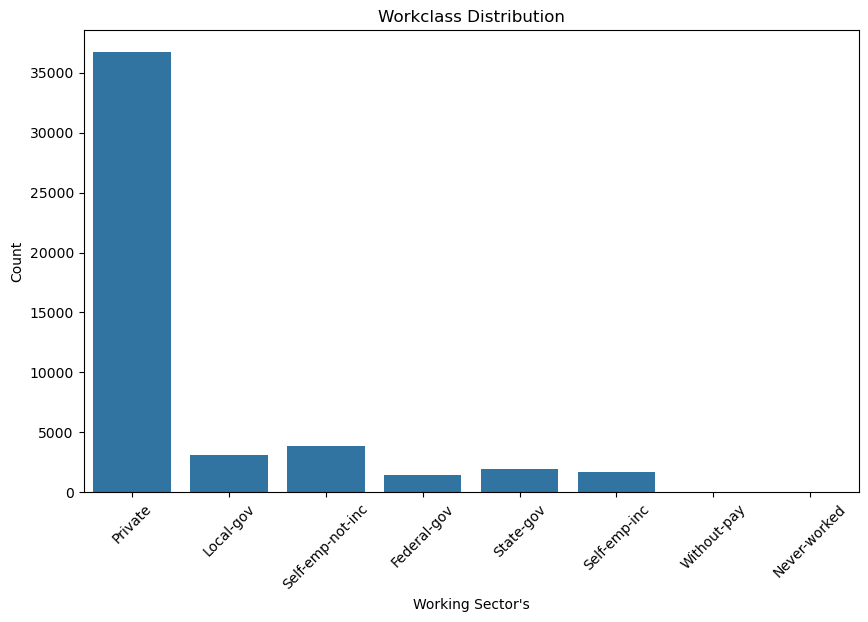

In [39]:
mt.figure(figsize=(10,6))
sb.countplot(data=adult, x='workclass')
mt.title('Workclass Distribution')
mt.xlabel("Working Sector's")
mt.ylabel('Count')
mt.xticks(rotation=45)
mt.show()

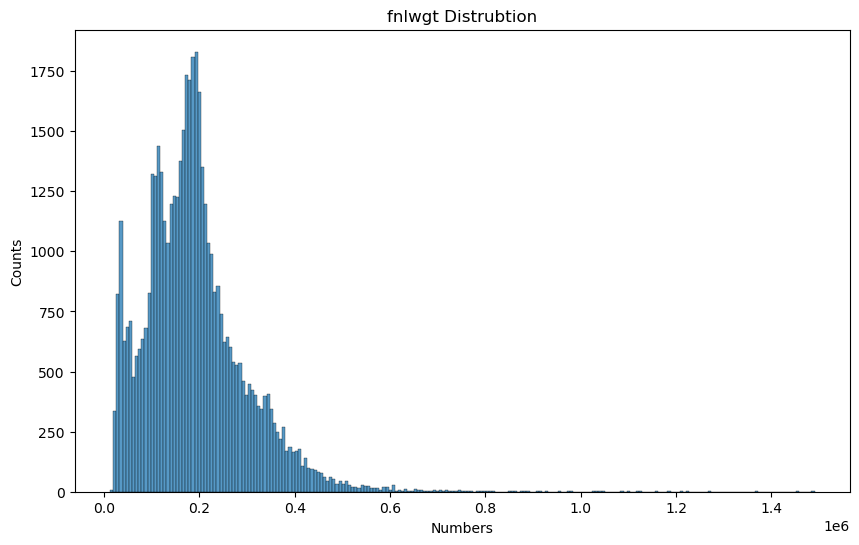

In [67]:
mt.figure(figsize=(10,6))
sb.histplot(data=adult , x='fnlwgt',)
mt.title("fnlwgt Distrubtion")
mt.xlabel("Numbers")
mt.ylabel("Counts")
mt.show()

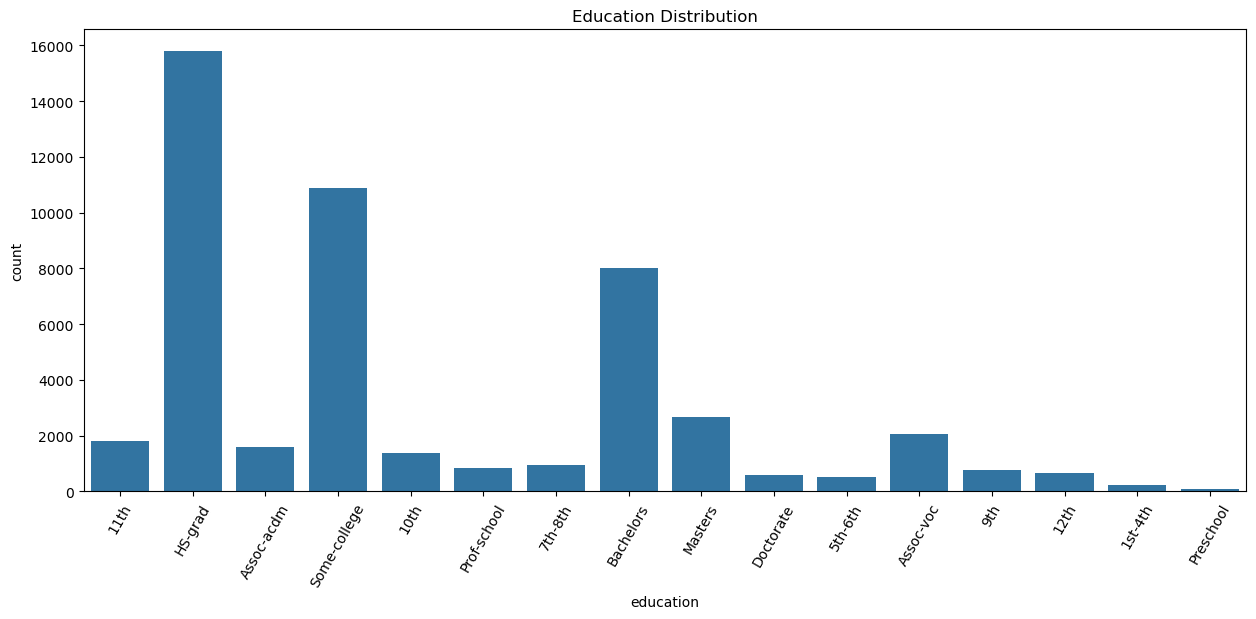

In [49]:
mt.figure(figsize=(15,6))
sb.countplot(data=adult , x='education')
mt.title("Education Distribution")
mt.xticks(rotation=60)
mt.show()

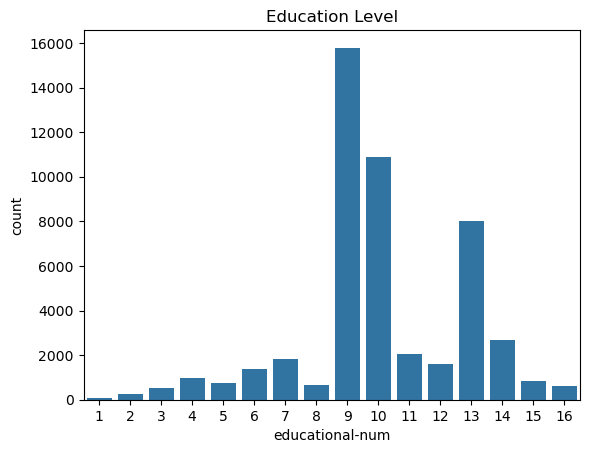

In [51]:
sb.countplot(data=adult, x='educational-num')
mt.title("Education Level")
mt.show()

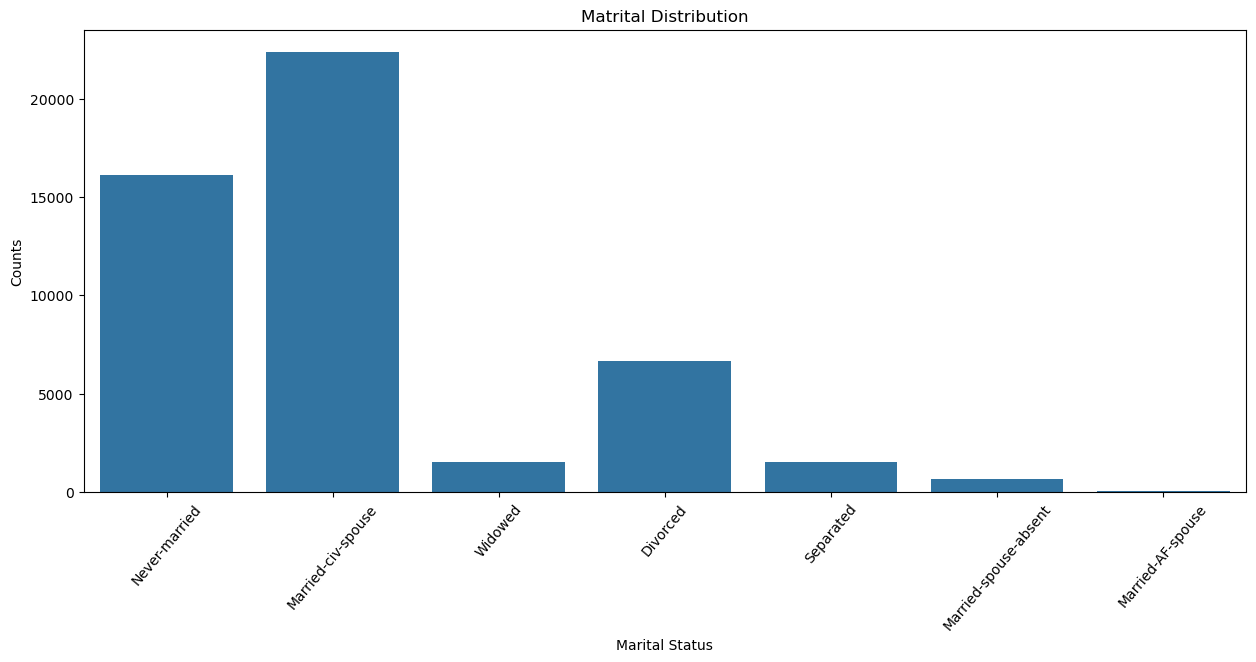

In [56]:
mt.figure(figsize=(15,6))
sb.countplot(data=adult,x='marital-status')
mt.title('Matrital Distribution')
mt.xlabel('Marital Status')
mt.ylabel('Counts')
mt.xticks(rotation=50)
mt.show()

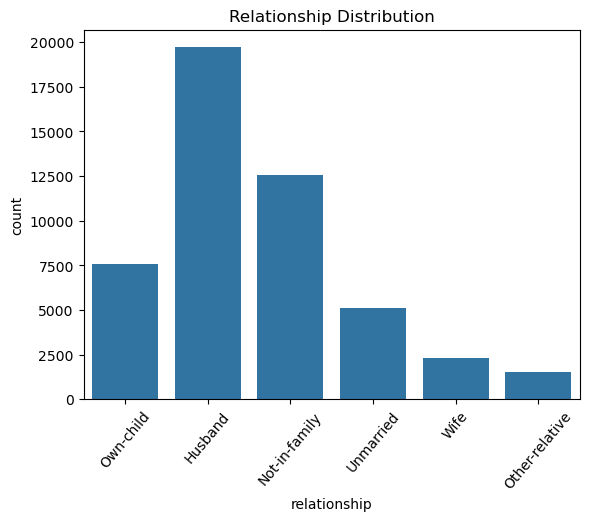

In [60]:
sb.countplot(data=adult , x='relationship')
mt.title('Relationship Distribution')
mt.xticks(rotation=50)
mt.show()

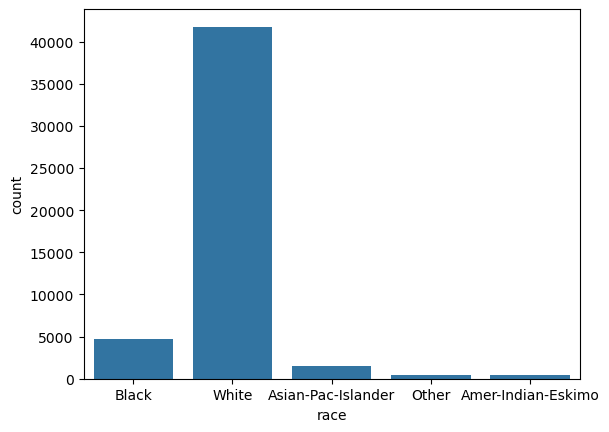

In [65]:
sb.countplot(data=adult, x='race')
mt.show()

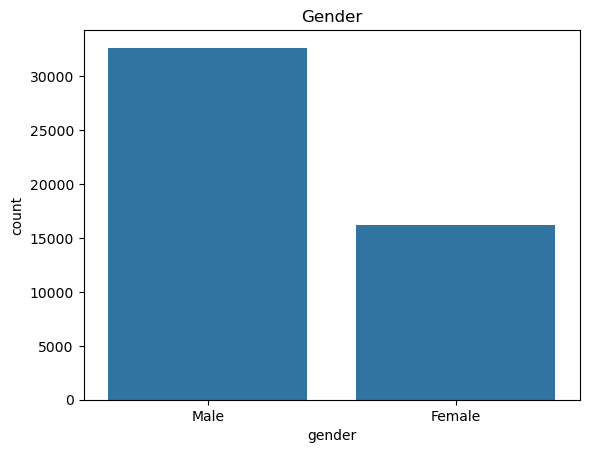

In [93]:
sb.countplot(data=adult , x='gender')
mt.title("Gender")
mt.show()

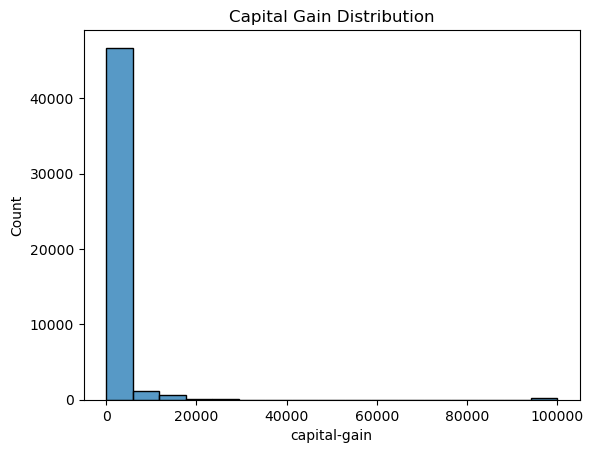

In [92]:
sb.histplot(data=adult, x='capital-gain')
mt.title('Capital Gain Distribution')
mt.show()

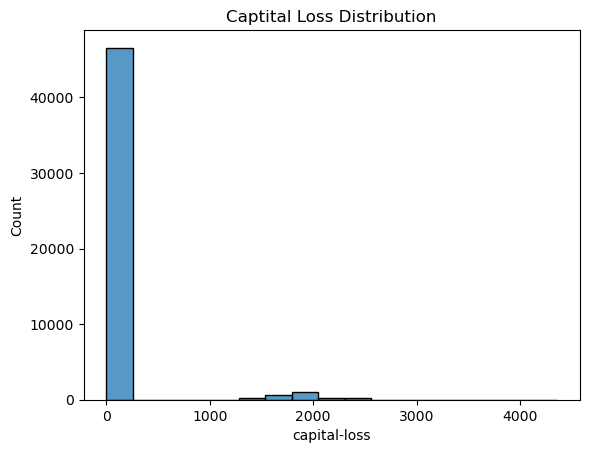

In [91]:
sb.histplot(data=adult, x='capital-loss')
mt.title("Captital Loss Distribution")
mt.show()

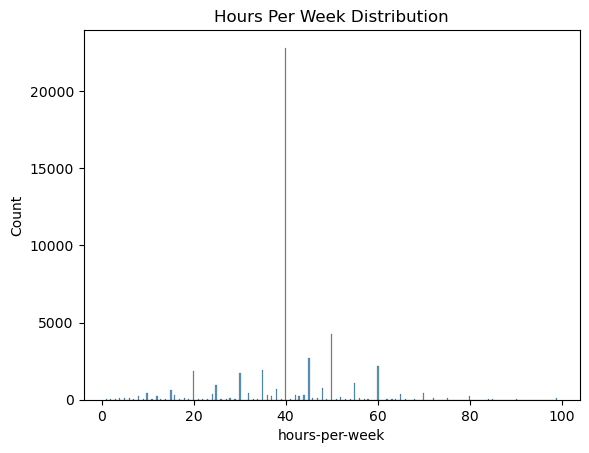

In [90]:
sb.histplot(data=adult , x='hours-per-week')
mt.title("Hours Per Week Distribution")
mt.show()

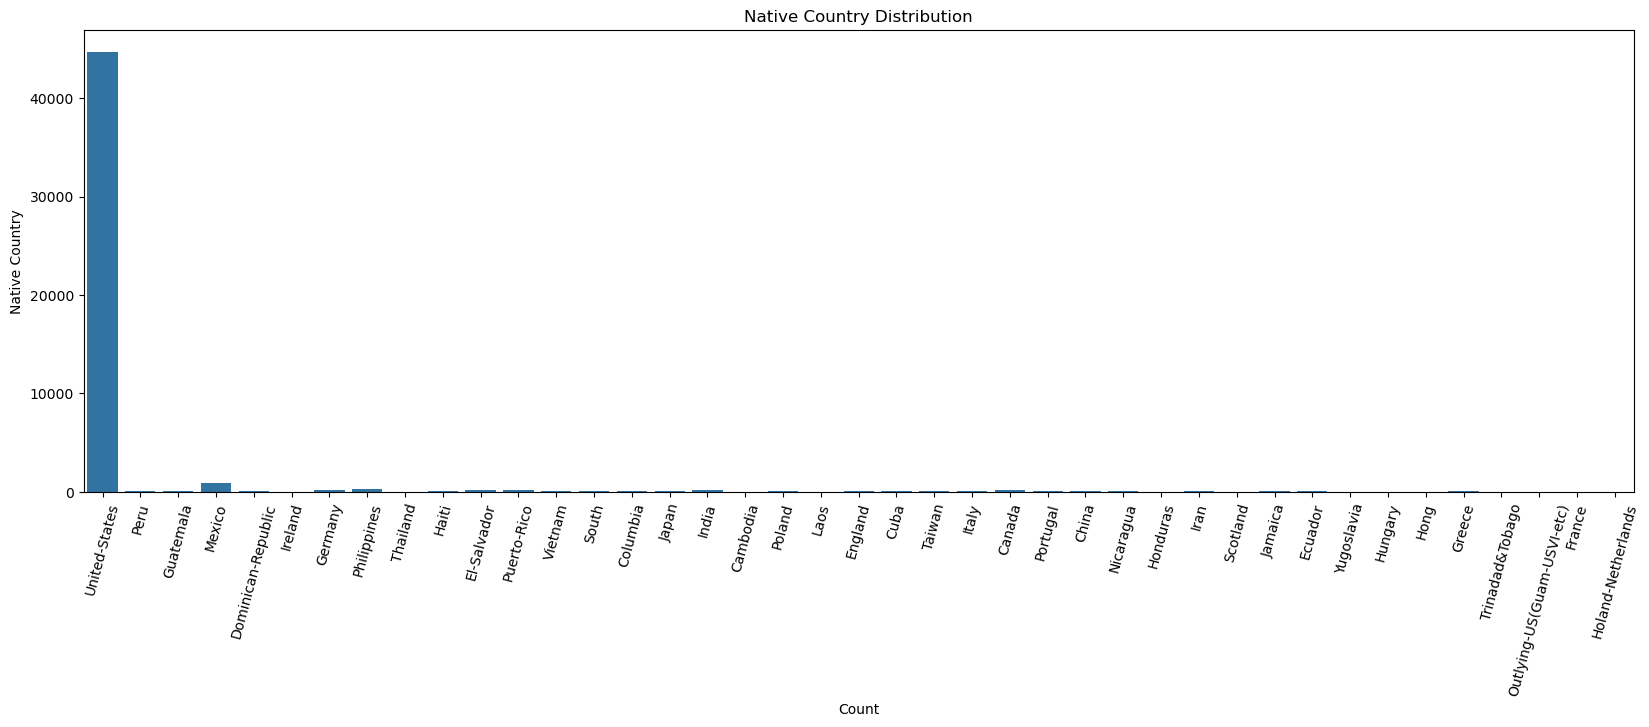

In [108]:
mt.figure(figsize=(20,6))

sb.countplot(data=adult , x='native-country')
mt.title("Native Country Distribution",)
mt.xlabel("Count")
mt.ylabel("Native Country")
mt.xticks(rotation=75)
mt.show()

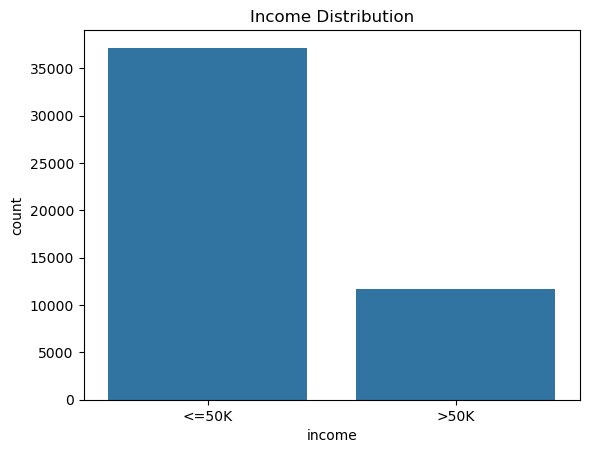

In [110]:
sb.countplot(data=adult , x = 'income')
mt.title('Income Distribution')
mt.show()

# 3. Hotel Dataset Data Cleaning And Visulization And Complete EDA

In [3]:
hotel = pd.read_csv('hotel_booking.csv')

In [4]:
hotel

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Transient,0.00,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Transient,0.00,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.00,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.00,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.00,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,Transient,96.14,0,0,Check-Out,2017-09-06,Claudia Johnson,Claudia.J@yahoo.com,403-092-5582,************8647
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,Transient,225.43,0,2,Check-Out,2017-09-07,Wesley Aguilar,WAguilar@xfinity.com,238-763-0612,************4333
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,Transient,157.71,0,4,Check-Out,2017-09-07,Mary Morales,Mary_Morales@hotmail.com,395-518-4100,************1821
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,Transient,104.40,0,0,Check-Out,2017-09-07,Caroline Conley MD,MD_Caroline@comcast.net,531-528-1017,************7860


In [5]:
hotel.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [6]:
hotel.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'name', 'email',
       'phone-number', 'credit_card'],
      dtype='object')

In [7]:
hotel.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [8]:
hotel['children'] = hotel['children'].fillna(hotel['children'].median())

In [9]:
hotel['country'] = hotel['children'].fillna(hotel['country'].mode()[0])

In [10]:
hotel['agent'] = hotel['agent'].fillna(hotel['agent'].median())

In [11]:
hotel['company'] = hotel['company'].fillna(hotel['company'].median())

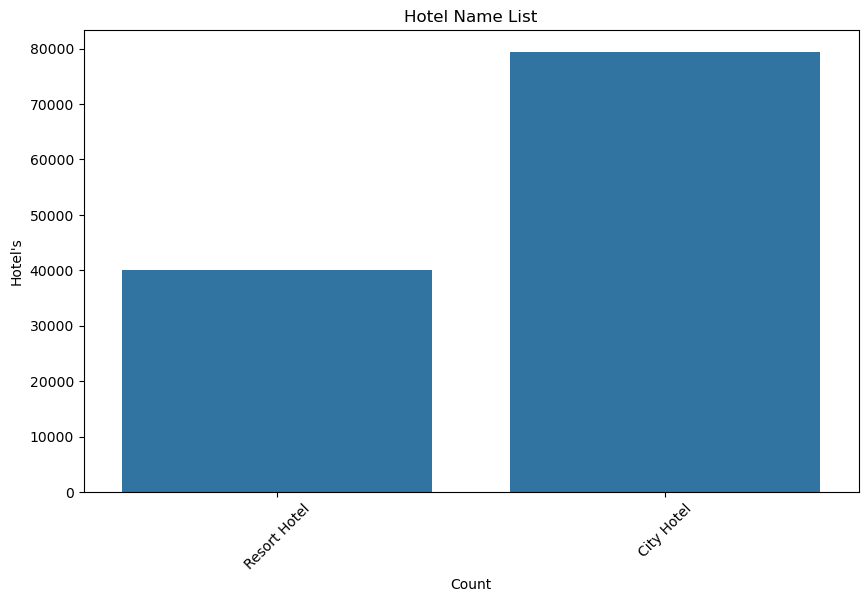

In [12]:
mt.figure(figsize=(10,6))

sb.countplot(data=hotel , x='hotel')
mt.title("Hotel Name List",)
mt.xlabel("Count")
mt.ylabel("Hotel's")
mt.xticks(rotation=45)
mt.show()

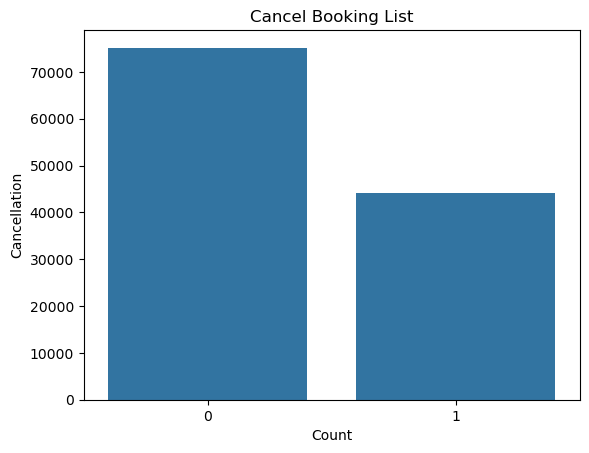

In [13]:
sb.countplot(data=hotel , x='is_canceled')
mt.title("Cancel Booking List",)
mt.xlabel("Count")
mt.ylabel("Cancellation")
mt.show()

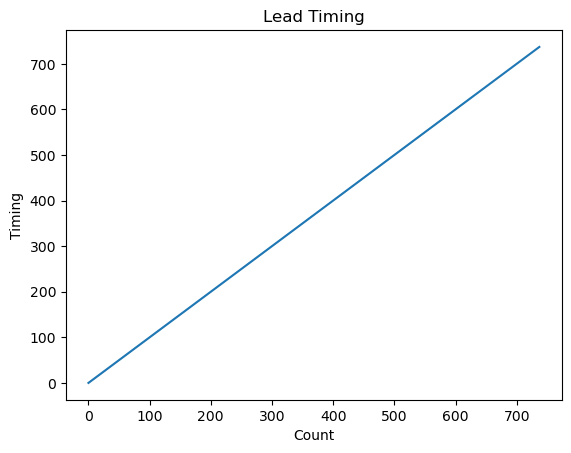

In [31]:
sb.lineplot(data=hotel ,x='lead_time' , y='lead_time')
mt.title("Lead Timing",)
mt.xlabel("Count")
mt.ylabel("Timing")
mt.show()

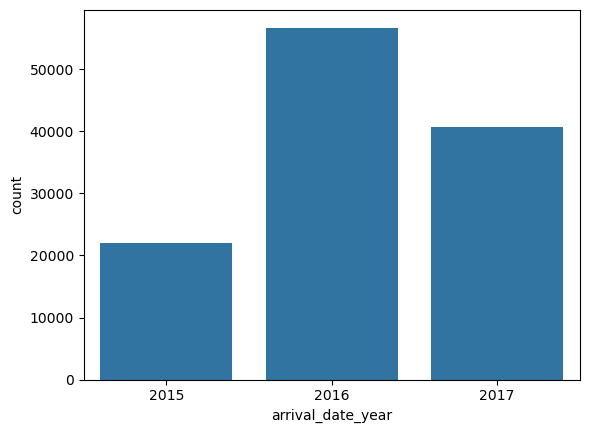

In [17]:
sb.countplot(data = hotel , x = 'arrival_date_year')
mt.show()

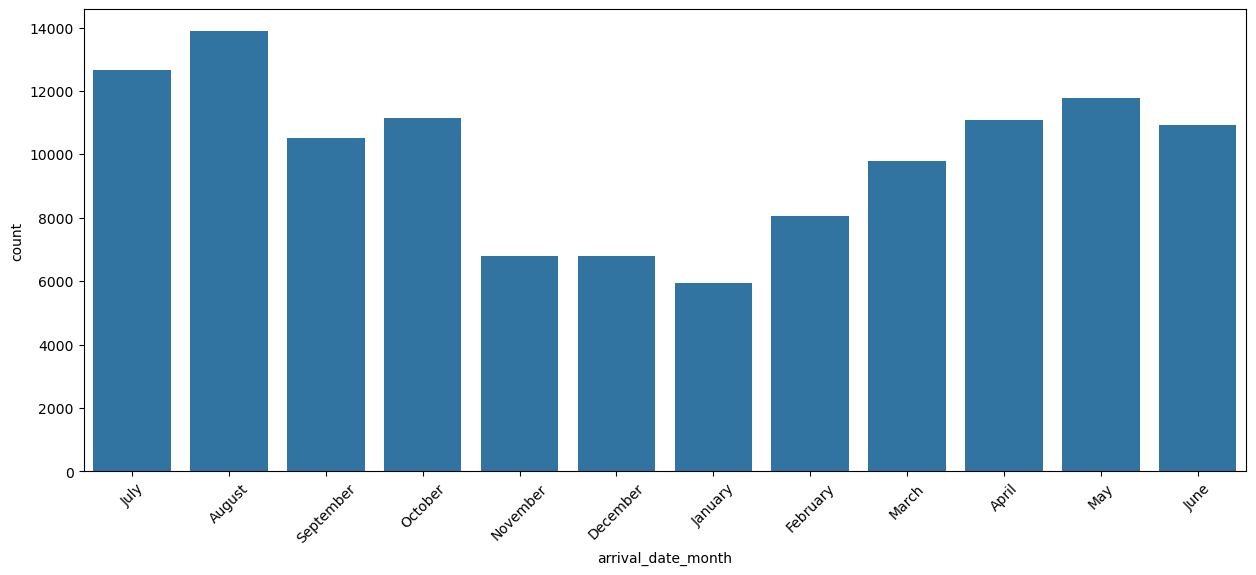

In [22]:
mt.figure(figsize=(15,6))
sb.countplot(data = hotel , x = 'arrival_date_month')
mt.xticks(rotation = 45)
mt.show()

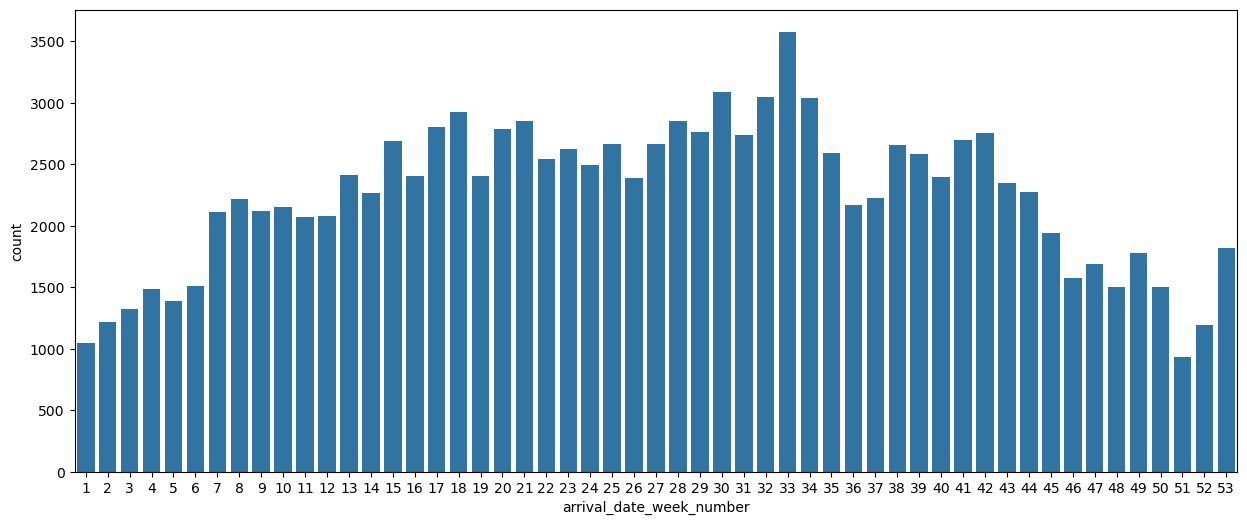

In [26]:
mt.figure(figsize=(15,6))
sb.countplot(data = hotel , x = 'arrival_date_week_number')
mt.show()

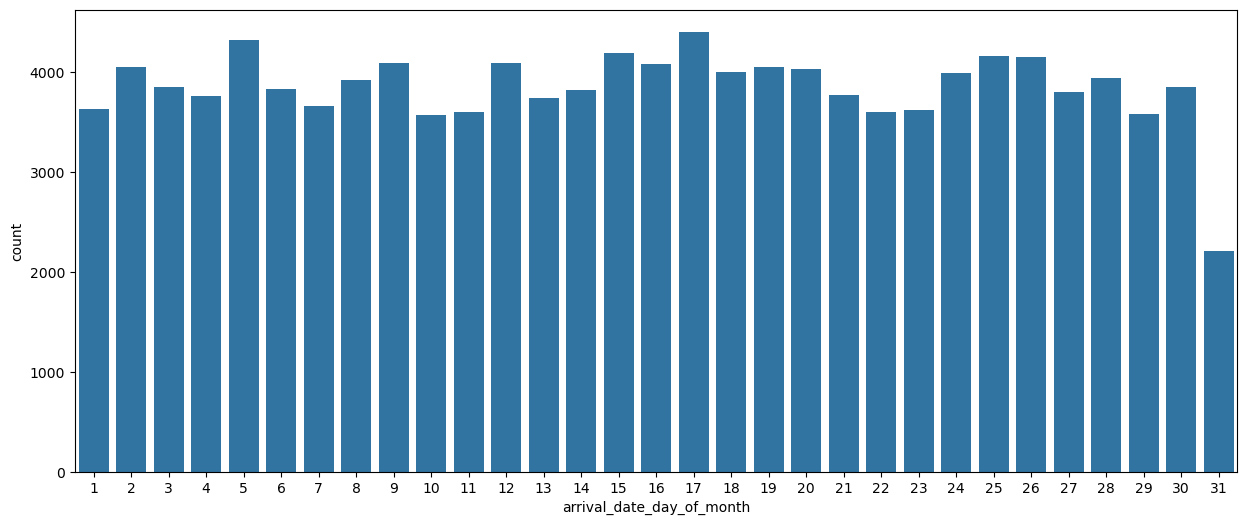

In [30]:
mt.figure(figsize=(15,6))
sb.countplot(data = hotel , x = 'arrival_date_day_of_month')
mt.show()

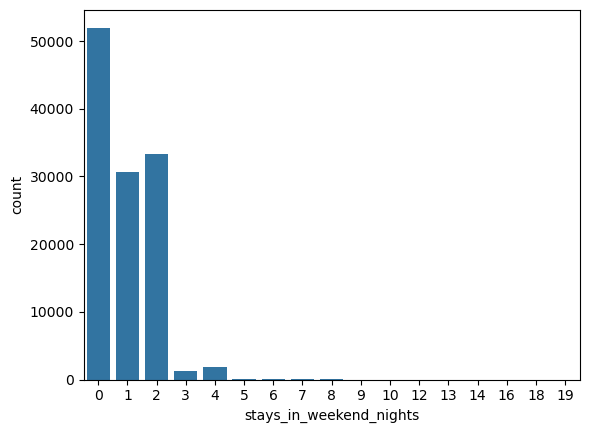

In [34]:
sb.countplot(data = hotel , x = 'stays_in_weekend_nights')
mt.show()

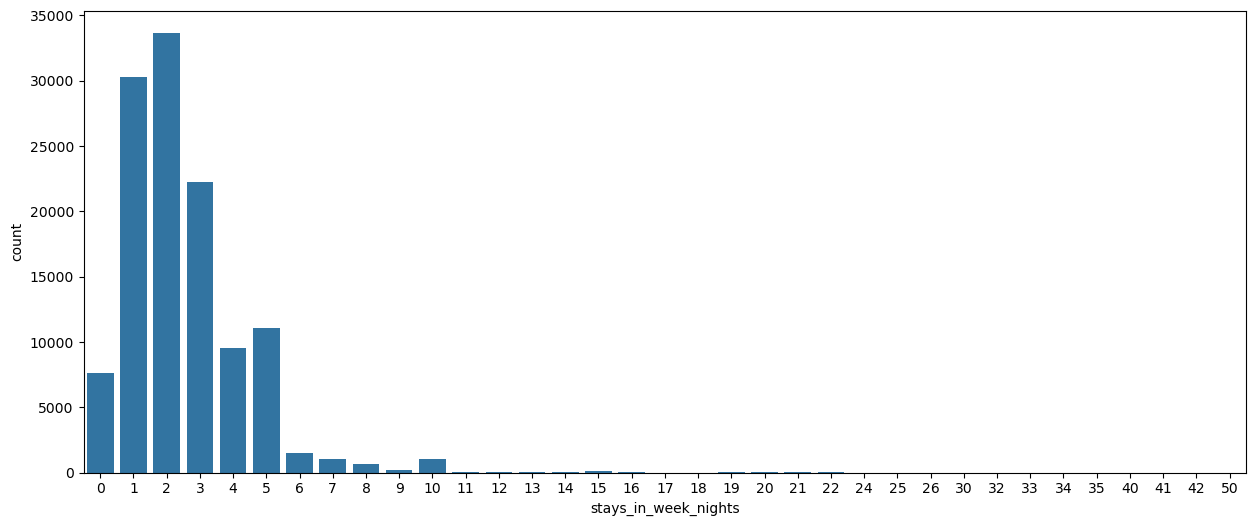

In [36]:
mt.figure(figsize= (15 , 6))
sb.countplot(data = hotel , x = 'stays_in_week_nights')
mt.show()

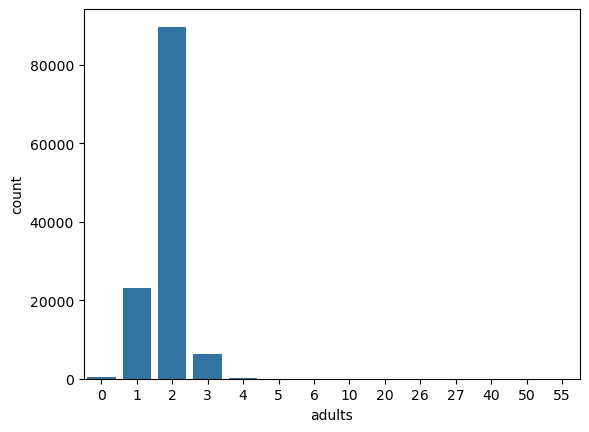

In [39]:
sb.countplot(data = hotel , x = 'adults')
mt.show()

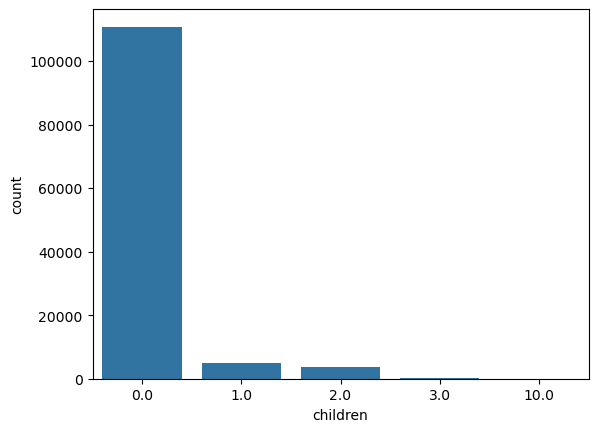

In [41]:
sb.countplot(data = hotel , x = 'children')
mt.show()

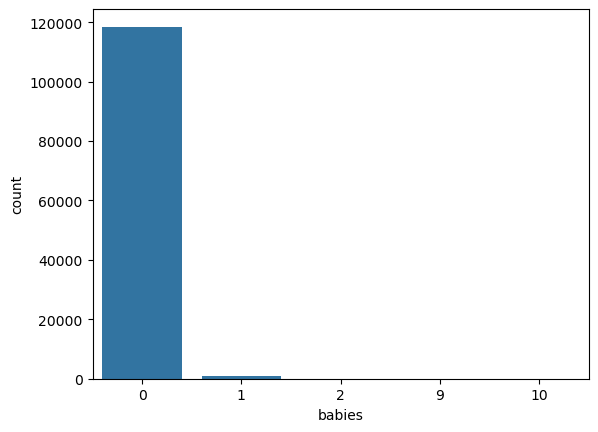

In [42]:
sb.countplot(data = hotel , x = 'babies')
mt.show()

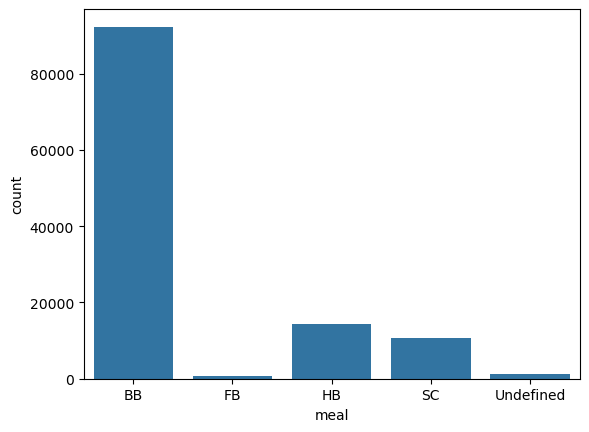

In [43]:
sb.countplot(data = hotel , x = 'meal')
mt.show()

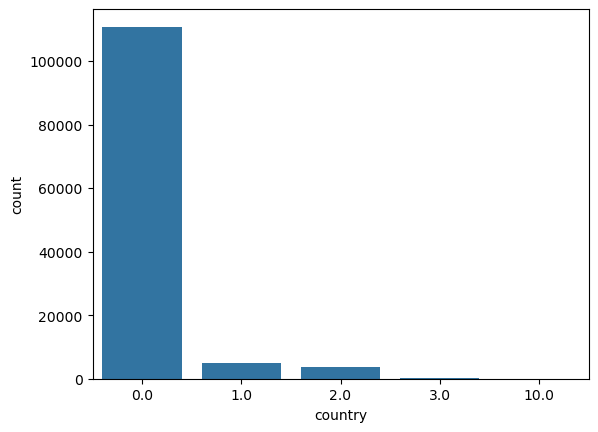

In [44]:
sb.countplot(data = hotel , x = 'country')
mt.show()

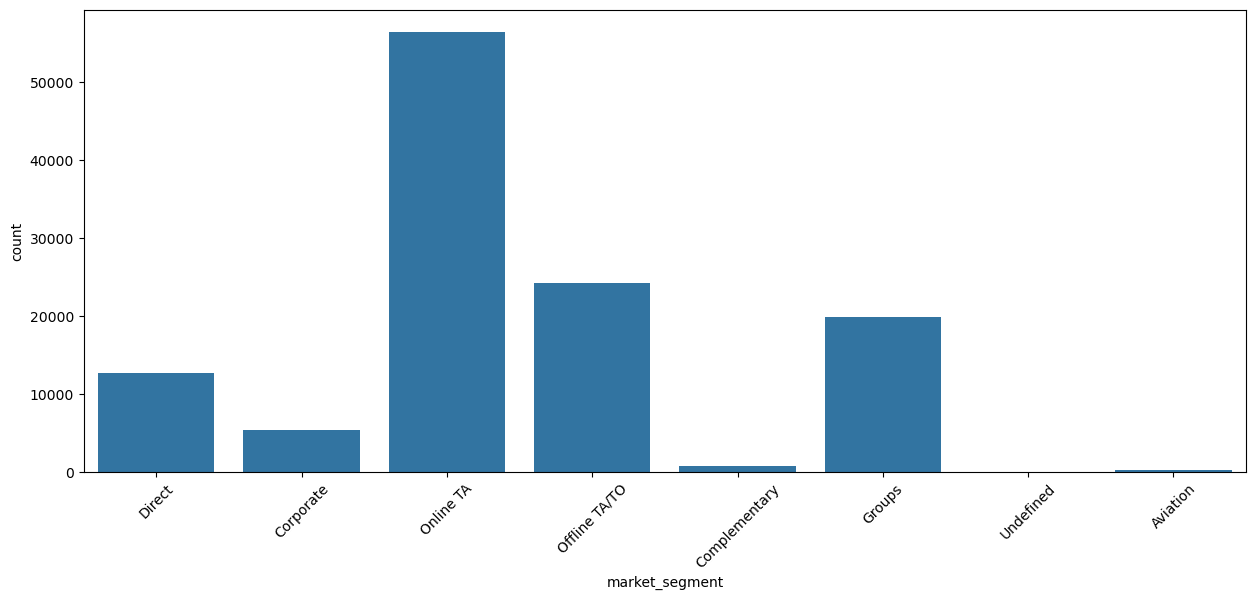

In [47]:
mt.figure(figsize=(15,6))
sb.countplot(data = hotel , x = 'market_segment')
mt.xticks(rotation = 45)
mt.show()

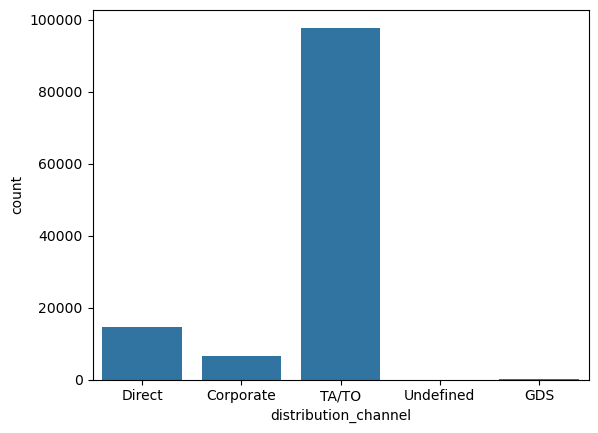

In [48]:
sb.countplot(data = hotel , x = 'distribution_channel')
mt.show()

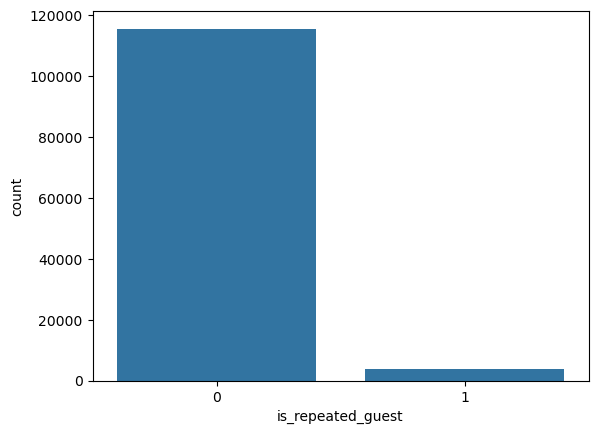

In [49]:
sb.countplot(data = hotel , x = 'is_repeated_guest')
mt.show()

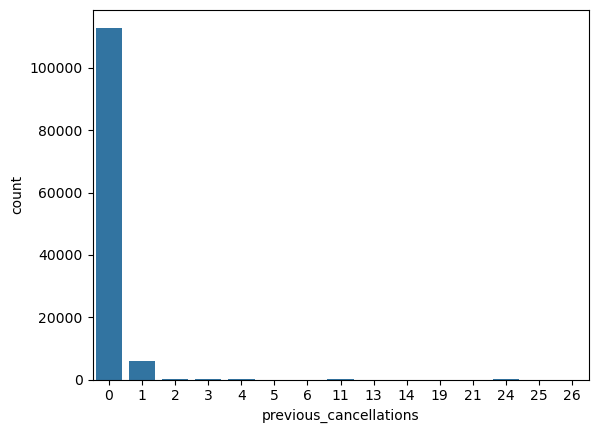

In [50]:
sb.countplot(data = hotel , x = 'previous_cancellations')
mt.show()

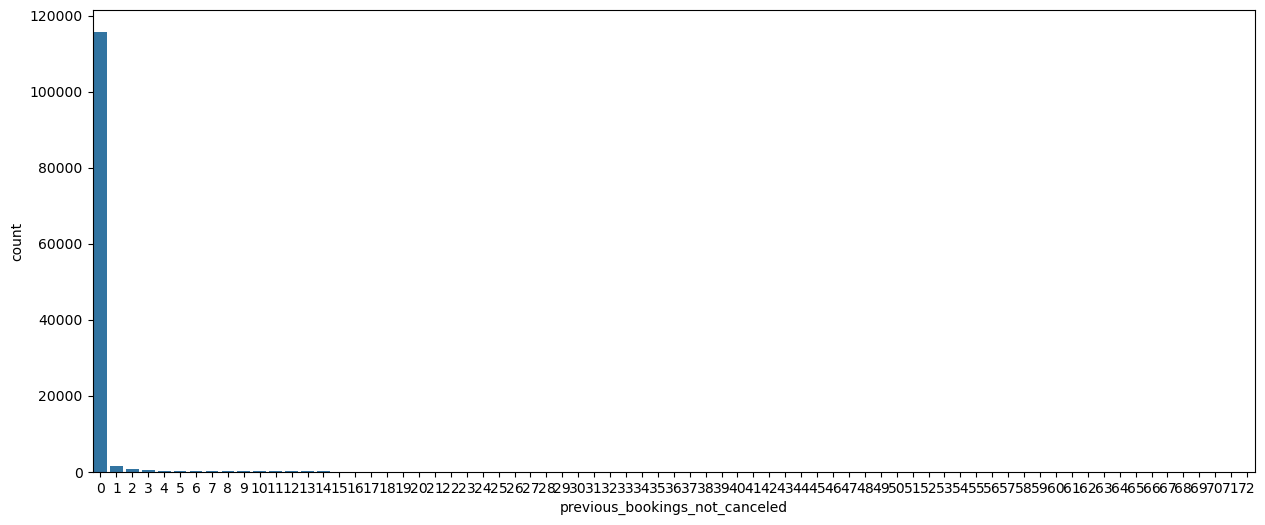

In [52]:
mt.figure(figsize=(15,6))
sb.countplot(data = hotel , x = 'previous_bookings_not_canceled')
mt.show()

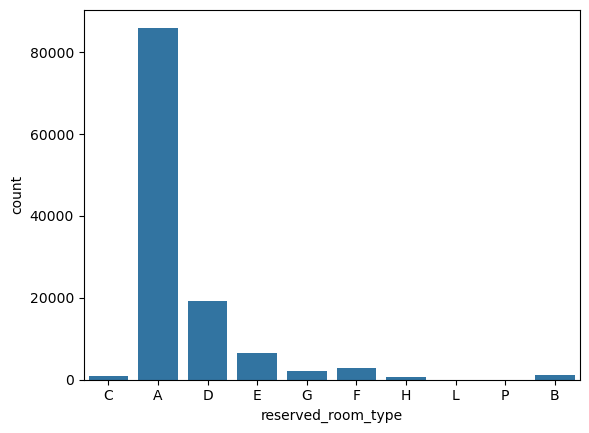

In [53]:
sb.countplot(data = hotel , x = 'reserved_room_type')
mt.show()

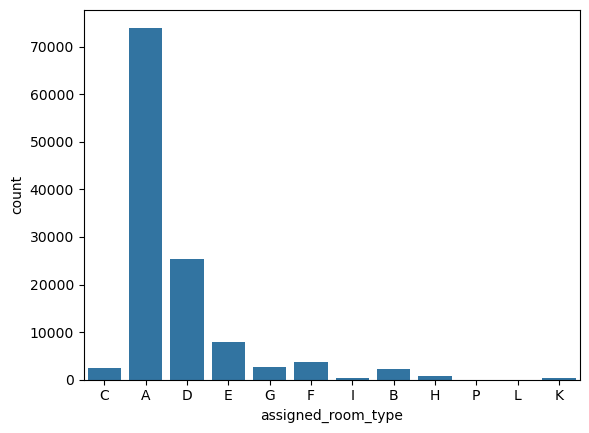

In [54]:
sb.countplot(data = hotel , x = 'assigned_room_type')
mt.show()

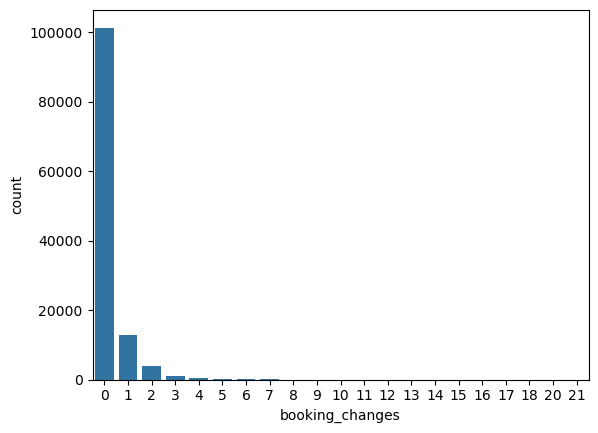

In [55]:
sb.countplot(data = hotel , x = 'booking_changes')
mt.show()

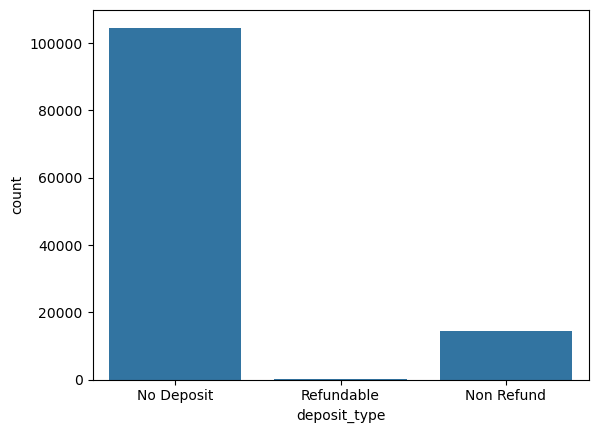

In [56]:
sb.countplot(data = hotel , x = 'deposit_type')
mt.show()

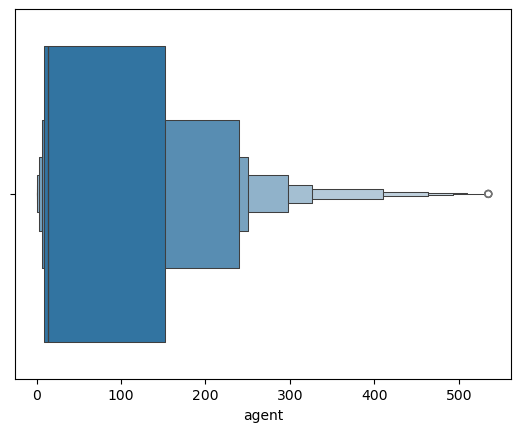

In [60]:
sb.boxenplot(data = hotel , x = 'agent')
mt.show()

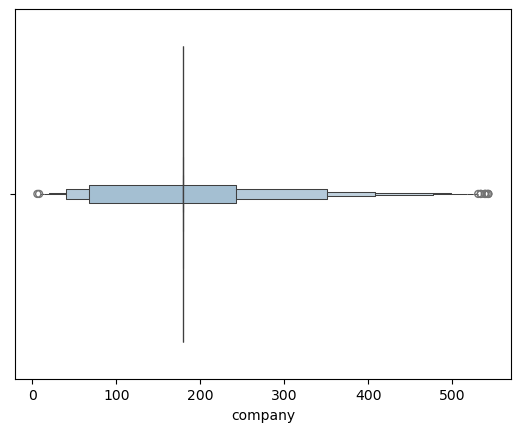

In [62]:
sb.boxenplot(data = hotel , x = 'company')
mt.show()

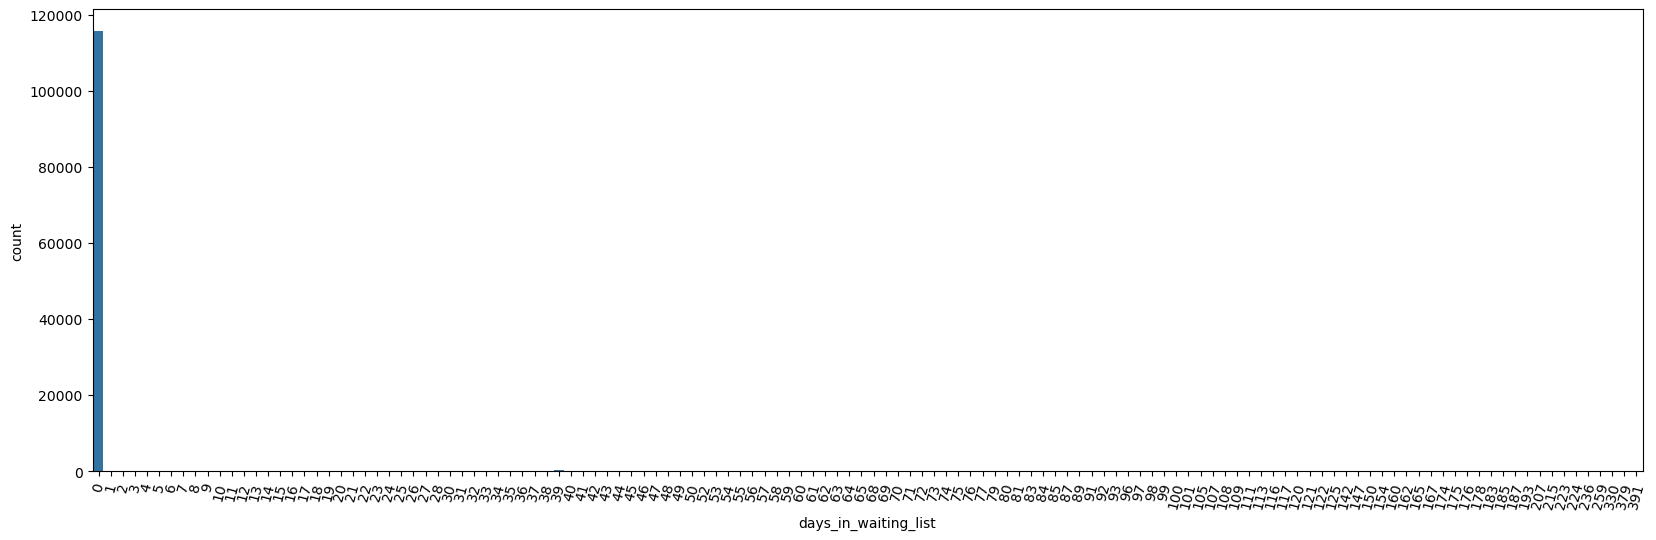

In [65]:
mt.figure(figsize=(20,6))
sb.countplot(data = hotel , x = 'days_in_waiting_list')
mt.xticks(rotation = 75)
mt.show()

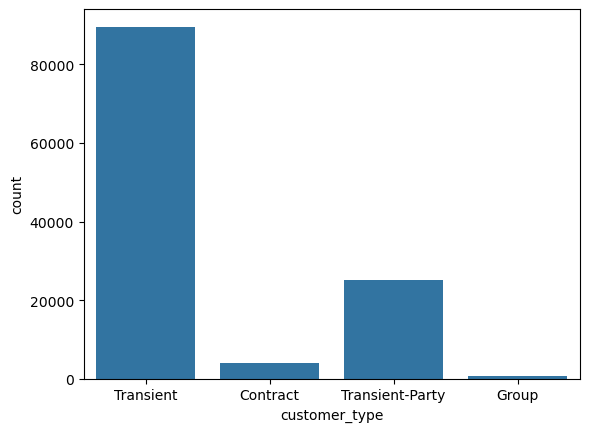

In [68]:
sb.countplot(data = hotel , x = 'customer_type')
mt.show()

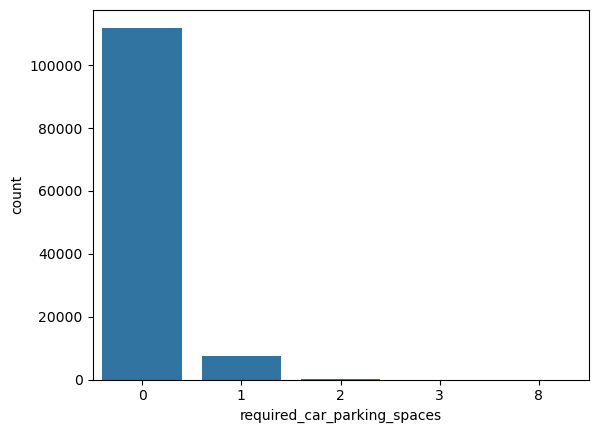

In [71]:
sb.countplot(data = hotel , x = 'required_car_parking_spaces')
mt.show()

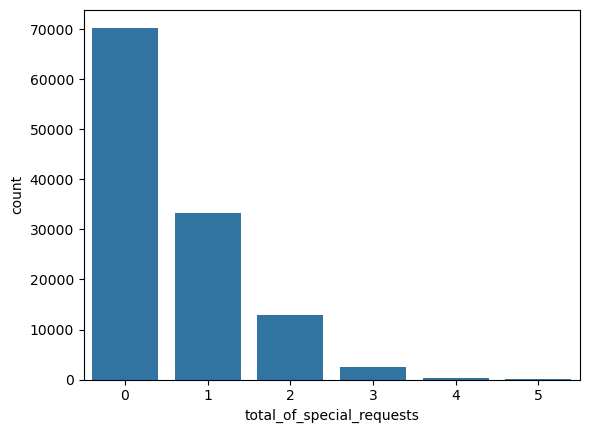

In [72]:
sb.countplot(data = hotel , x = 'total_of_special_requests')
mt.show()

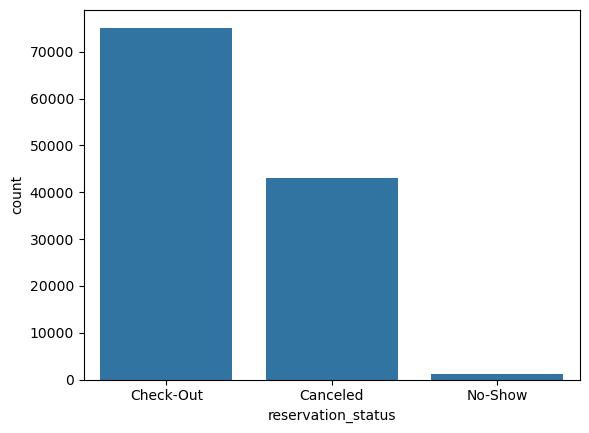

In [73]:
sb.countplot(data = hotel , x = 'reservation_status')
mt.show()

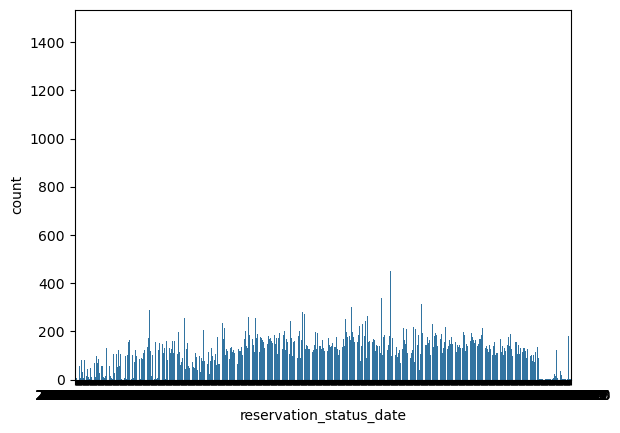

In [74]:
sb.countplot(data = hotel , x = 'reservation_status_date')
mt.show()